# retail_sales_analysis.ipynb


In [ ]:
import os
import pandas as pd

# Показываем список всех файлов, которые сейчас видит Colab
print('Файлы в папке Colab:', os.listdir())

products = pd.read_excel('/products.xlsx')
orders = pd.read_excel('/orders.xlsx')

# Проверяем первые 3 строки справочника товаров
products.head(3)

Файлы в папке Colab: ['.config', 'sample_data']


,product_id,level1,level2,name
0,1,Гигиена,Бритье,Кассеты для бритья Gillette Fusion ProGlide Po...
1,2,Мучные кондитерские изделия,Мучные кондитерские изделия,Печенье Бодрость
2,3,Мясная гастрономия,"Сосиски, сардельки",Сосиски Стародворье


,Категория,Продано штук
1,Безалкогольные напитки,534
11,Молочная продукция,483
19,Свежие овощи,262
10,Кулинария,250
0,Бакалея,239
25,Хлеб и хлебобулочные изделия,218
21,Снэки,212
20,Свежие фрукты,184
6,Замороженная продукция,175
7,Кондитерские изделия,138


/tmp/ipykernel_1821/3209891599.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


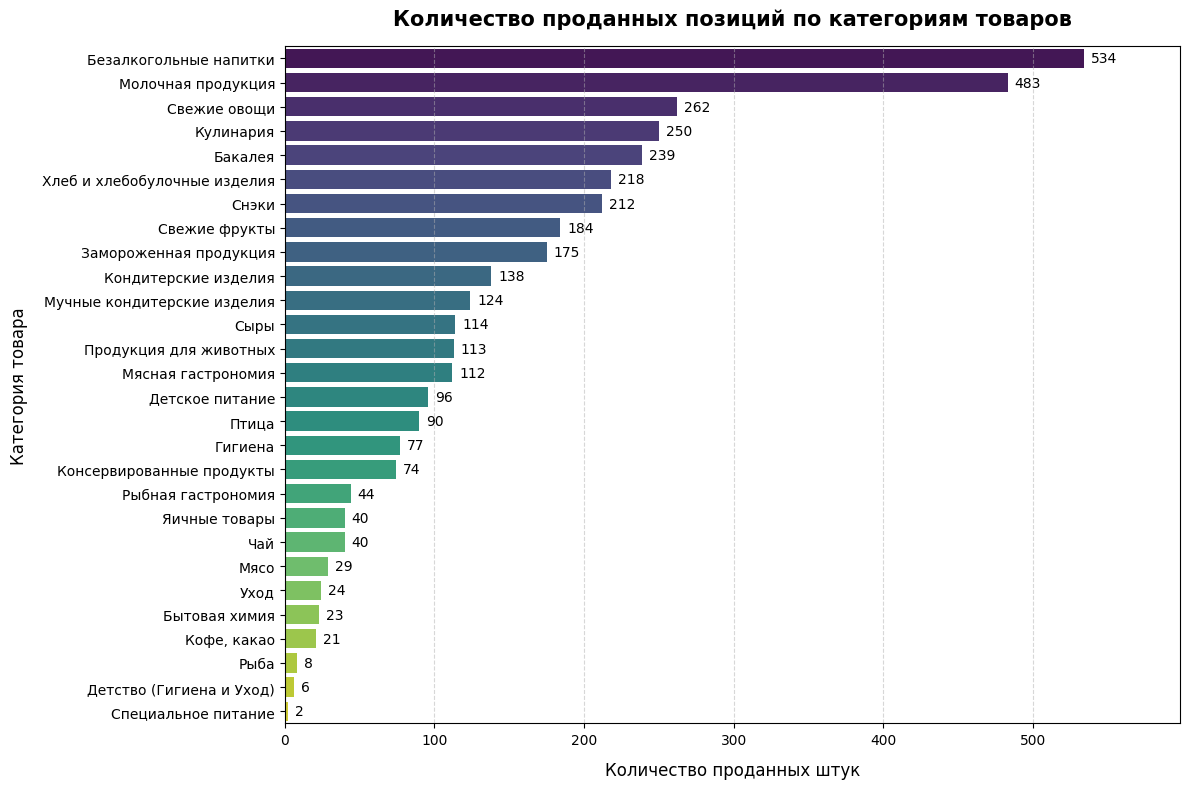

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Объединяем заказы и справочник товаров по общему столбцу product_id
df = pd.merge(orders, products, on='product_id', how='left')

# 2. Считаем количество проданных штук по каждой категории (level1) и сортируем по убыванию
category_sales = (
    df.groupby('level1', as_index=False)['quantity']
    .sum()
    .sort_values(by='quantity', ascending=False)
)
category_sales.columns = ['Категория', 'Продано штук']
# Выводим таблицу (первая строчка покажет категорию-лидера)
display(category_sales)

# 3. Строим читаемый горизонтальный bar chart
plt.figure(figsize=(12, 8))
ax = sns.barplot(
    data=category_sales, x='Продано штук', y='Категория', palette='viridis'
)
# Подписываем точное количество штук рядом с каждым столбцом
for container in ax.containers:
  ax.bar_label(container, fmt='%.0f', padding=5, fontsize=10)

plt.title(
    'Количество проданных позиций по категориям товаров',
    fontsize=15,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Количество проданных штук', fontsize=12, labelpad=10)
plt.ylabel('Категория товара', fontsize=12, labelpad=10)

# Увеличиваем отступ справа, чтобы цифры у самого длинного столбца не упирались в рамку
plt.xlim(0, category_sales['Продано штук'].max() * 1.12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Если таблица df еще не объединена, раскомментируйте строку ниже:
# df = pd.merge(orders, products, on='product_id', how='left')

# 1. Группируем по категории (level1) и подкатегории (level2), считаем сумму штук
subcat_sales = (
    df.groupby(['level1', 'level2'], as_index=False)['quantity']
    .sum()
    .sort_values(by=['level1', 'quantity'], ascending=[True, False])
)
# 2. Добавляем долю (%) каждой подкатегории внутри своей категории level1
subcat_sales['Доля в категории, %'] = (
    subcat_sales['quantity']
    / subcat_sales.groupby('level1')['quantity'].transform('sum')
    * 100
).round(2)

# 3. Переименовываем столбцы для наглядности
subcat_sales.columns = [
    'Категория (level1)',
    'Подкатегория (level2)',
    'Продано штук',
    'Доля в категории, %',
]
# Чтобы в Colab отобразились все строки таблицы без сокращения точками (...)
pd.set_option('display.max_rows', None)

# Выводим расчетную таблицу
display(subcat_sales)

,Категория (level1),Подкатегория (level2),Продано штук,"Доля в категории, %"
10,Бакалея,Сухие блюда быстрого приготовления,38,15.90
3,Бакалея,"Крупы, бобовые",30,12.55
1,Бакалея,Зерновые для завтраков,24,10.04
4,Бакалея,Макаронные изделия,24,10.04
9,Бакалея,Соусы,24,10.04
2,Бакалея,Ингредиенты для готовки,21,8.79
6,Бакалея,Пряности,21,8.79
5,Бакалея,Мука и мучные смеси,19,7.95
7,Бакалея,Растительные масла,18,7.53
8,Бакалея,Сахар,11,4.60


Топ-3 категории по продажам: ['Безалкогольные напитки', 'Молочная продукция', 'Свежие овощи']


/tmp/ipykernel_1821/3899019115.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
/tmp/ipykernel_1821/3899019115.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
/tmp/ipykernel_1821/3899019115.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


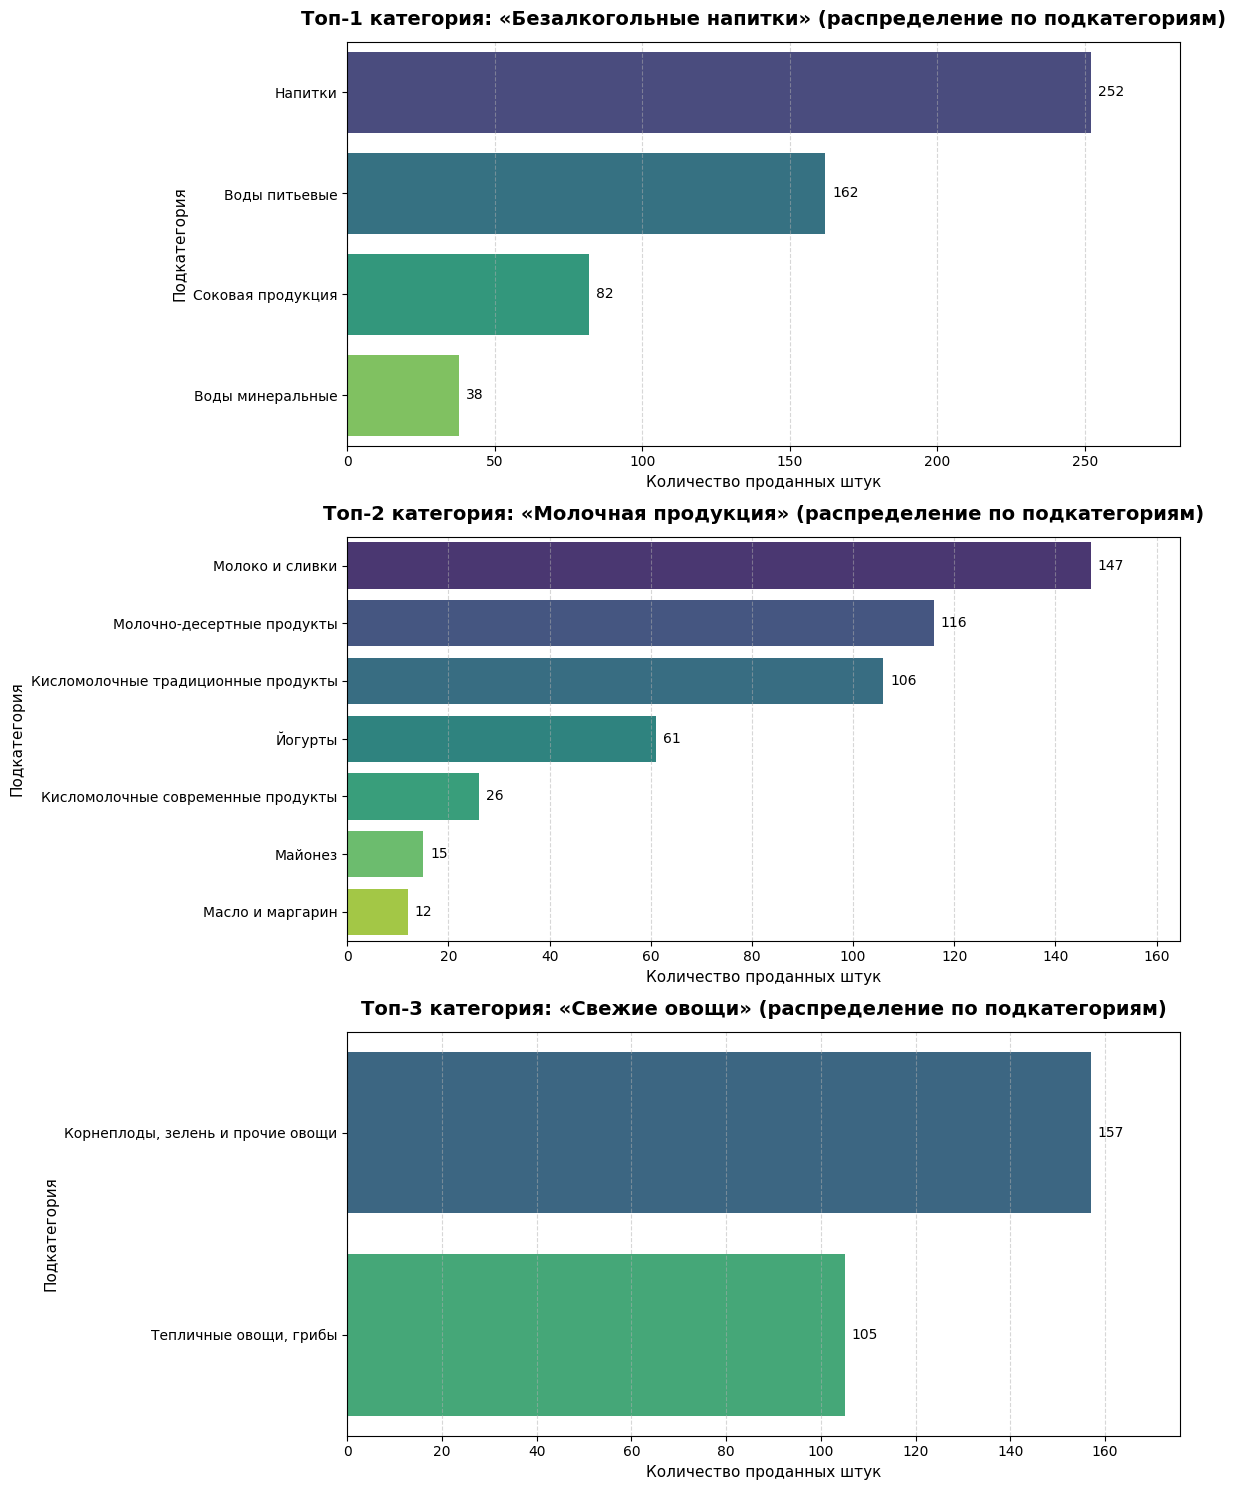

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Находим названия топ-3 категорий по общему количеству проданных штук
top3_categories = (
    df.groupby('level1')['quantity']
    .sum()
    .sort_values(ascending=False)
    .head(3)
    .index.tolist()
)

print('Топ-3 категории по продажам:', top3_categories)
# 2. Фильтруем данные только по топ-3 категориям и группируем по подкатегориям
top3_subcats = (
    df[df['level1'].isin(top3_categories)]
    .groupby(['level1', 'level2'], as_index=False)['quantity']
    .sum()
)

# 3. Строим 3 отдельных горизонтальных графика (один под другим для удобного чтения длинных названий)
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 15))

for i, category in enumerate(top3_categories):
  # Берем данные только для текущей категории и сортируем по убыванию продаж
  cat_data = top3_subcats[top3_subcats['level1'] == category].sort_values(
      by='quantity', ascending=False
  )

  # Рисуем горизонтальный bar chart
  ax = sns.barplot(
      data=cat_data, x='quantity', y='level2', ax=axes[i], palette='viridis'
  )
   # Добавляем точные числа рядом со столбцами
  for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=5, fontsize=10)

  # Настраиваем заголовки и оси для каждого подграфика
  ax.set_title(
      f'Топ-{i+1} категория: «{category}» (распределение по подкатегориям)',
      fontsize=14,
      fontweight='bold',
      pad=12,
  )
  ax.set_xlabel('Количество проданных штук', fontsize=11)
  ax.set_ylabel('Подкатегория', fontsize=11)
# Добавляем запас справа 12%, чтобы цифры не выходили за рамку
  ax.set_xlim(0, cat_data['quantity'].max() * 1.12)
  ax.grid(axis='x', linestyle='--', alpha=0.5)

# Автоматически выравниваем расстояния между графиками, чтобы заголовки не перекрывались
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. Переводим столбец с датой и временем в формат datetime (если это еще не сделано)
orders['accepted_at'] = pd.to_datetime(orders['accepted_at'])

# 2. Считаем итоговую стоимость каждой строчки в заказе (текущая цена * количество)
orders['total_sum'] = orders['price'] * orders['quantity']

# 3. Фильтруем заказы только за 13 января 2022 года
orders_13_jan = orders[orders['accepted_at'].dt.date == pd.to_datetime('2022-01-13').date()]

# 4. Группируем по номеру чека (order_id), чтобы получить полную сумму каждого чека
checks_13_jan = orders_13_jan.groupby('order_id')['total_sum'].sum()
# 5. Считаем средний чек (среднее арифметическое по всем чекам за день)
avg_check = checks_13_jan.mean()

print(f'Количество чеков за 13.01.2022: {len(checks_13_jan)}')
print(f'Общая выручка за день: {checks_13_jan.sum():.2f}')
print(f'Средний чек 13.01.2022: {avg_check:.2f}')

Количество чеков за 13.01.2022: 544
Общая выручка за день: 498107.00
Средний чек 13.01.2022: 915.64


,is_promo,quantity,"Доля, %"
0,Без промоакции,79,69.3
1,По промоакции,35,30.7


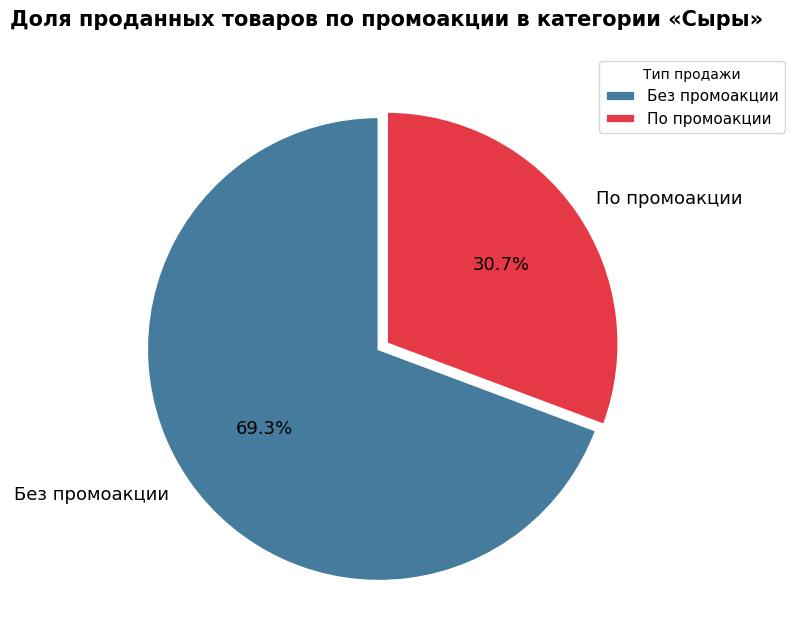

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Если таблица df еще не объединена, раскомментируйте строку ниже:
# df = pd.merge(orders, products, on='product_id', how='left')

# 1. Фильтруем данные только по категории «Сыры»
cheese_df = df[df['level1'] == 'Сыры'].copy()

# 2. Определяем, продан ли товар по промоакции (базовая цена не равна фактической)
cheese_df['is_promo'] = np.where(
    cheese_df['regular_price'] != cheese_df['price'],
    'По промоакции',
    'Без промоакции',
)

# 3. Считаем количество проданных штук (quantity) по группам и долю в процентах
promo_summary = cheese_df.groupby('is_promo', as_index=False)['quantity'].sum()
promo_summary['Доля, %'] = (
    promo_summary['quantity'] / promo_summary['quantity'].sum() * 100
).round(2)

# Выводим расчетную таблицу на экран
display(promo_summary)

# 4. Строим круговую диаграмму (pie chart)
plt.figure(figsize=(8, 8))

plt.pie(
    promo_summary['quantity'],
    labels=promo_summary['is_promo'],
    autopct='%1.1f%%',  # Выводит доли в процентах с одним знаком после запятой
    startangle=90,  # Начинает отрисовку сверху (от 12 часов)
    colors=['#457B9D', '#E63946'],  # Спокойный синий и акцентный красный
    explode=(0.04, 0),  # Слегка отделяет один сектор для наглядности
    textprops={'fontsize': 13},  # Размер шрифта подписей и процентов
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2,
    },  # Белая граница между секторами
)

plt.title(
    'Доля проданных товаров по промоакции в категории «Сыры»',
    fontsize=15,
    fontweight='bold',
    pad=20,
)
plt.legend(
    title='Тип продажи', loc='upper right', fontsize=11, bbox_to_anchor=(1.2, 1)
)
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import pandas as pd

# 1. Считаем выручку по каждой строке (если еще не посчитана)
df['revenue'] = df['price'] * df['quantity']

# 2. Группируем данные по подкатегориям level2 (при необходимости можно заменить на 'name' или 'level1')
abc_df = df.groupby('level2', as_index=False)[['quantity', 'revenue']].sum()


# Функция для присвоения группы A, B или C по накопительной доле
def get_abc_group(cum_share):
  if cum_share <= 0.80:
    return 'A'
  elif cum_share <= 0.95:
    return 'B'
  else:
    return 'C'


# --- 3. ABC-анализ по количеству продаж (quantity) ---
abc_df = abc_df.sort_values(by='quantity', ascending=False)
abc_df['qty_share'] = abc_df['quantity'] / abc_df['quantity'].sum()
abc_df['qty_cum_share'] = abc_df['qty_share'].cumsum()
abc_df['ABC_quantity'] = abc_df['qty_cum_share'].apply(get_abc_group)

# --- 4. ABC-анализ по сумме продаж (revenue) ---
abc_df = abc_df.sort_values(by='revenue', ascending=False)
abc_df['rev_share'] = abc_df['revenue'] / abc_df['revenue'].sum()
abc_df['rev_cum_share'] = abc_df['rev_share'].cumsum()
abc_df['ABC_revenue'] = abc_df['rev_cum_share'].apply(get_abc_group)

# --- 5. Создаем итоговый столбец на основе двух анализов (например, AA, AB, BC) ---
abc_df['ABC_total'] = abc_df['ABC_quantity'] + abc_df['ABC_revenue']

# Оставляем только нужные для отчета столбцы и выводим таблицу
result_abc = abc_df[[
    'level2',
    'quantity',
    'ABC_quantity',
    'revenue',
    'ABC_revenue',
    'ABC_total',
]].copy()
result_abc.columns = [
    'Подкатегория',
    'Количество, шт.',
    'Группа (кол-во)',
    'Сумма продаж, руб.',
    'Группа (сумма)',
    'Итоговая группа ABC',
]

# Выводим итоговую таблицу (отсортированную по сумме продаж)
display(result_abc)

# Дополнительно: посмотрим, сколько подкатегорий попало в каждую итоговую группу (AA, AB и т.д.)
print('\nРаспределение по итоговым группам:')
print(result_abc['Итоговая группа ABC'].value_counts())


,Подкатегория,"Количество, шт.",Группа (кол-во),"Сумма продаж, руб.",Группа (сумма),Итоговая группа ABC
10,Готовые блюда,248,A,40356,A,AA
51,Напитки,252,A,24123,A,AA
50,Мясо птицы охлажденное,90,A,22349,A,AA
85,"Тепличные овощи, грибы",105,A,18329,A,AA
72,Снэки соленые,180,A,17293,A,AA
94,"Цитрусовые, семечковые и прочие плоды",108,A,16818,A,AA
18,Замороженные полуфабрикаты,73,A,15374,A,AA
40,Молоко и сливки,147,A,14902,A,AA
33,"Корнеплоды, зелень и прочие овощи",157,A,14893,A,AA
92,Хлеб и хлебобулочные изделия,218,A,14724,A,AA



Распределение по итоговым группам:
Итоговая группа ABC
CC    32
AA    23
BB    15
CB    10
BA     9
AB     5
BC     4
AC     2
Name: count, dtype: int64


In [ ]:
import os
import pandas as pd

# Показываем список всех файлов, которые сейчас видит Colab
print('Файлы в папке Colab:', os.listdir())

products = pd.read_excel('/products.xlsx')
orders = pd.read_excel('/orders.xlsx')

# Проверяем первые 3 строки справочника товаров
products.head(3)

Файлы в папке Colab: ['.config', 'sample_data']


,product_id,level1,level2,name
0,1,Гигиена,Бритье,Кассеты для бритья Gillette Fusion ProGlide Po...
1,2,Мучные кондитерские изделия,Мучные кондитерские изделия,Печенье Бодрость
2,3,Мясная гастрономия,"Сосиски, сардельки",Сосиски Стародворье


,Категория,Продано штук
1,Безалкогольные напитки,534
11,Молочная продукция,483
19,Свежие овощи,262
10,Кулинария,250
0,Бакалея,239
25,Хлеб и хлебобулочные изделия,218
21,Снэки,212
20,Свежие фрукты,184
6,Замороженная продукция,175
7,Кондитерские изделия,138


/tmp/ipykernel_1821/3209891599.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


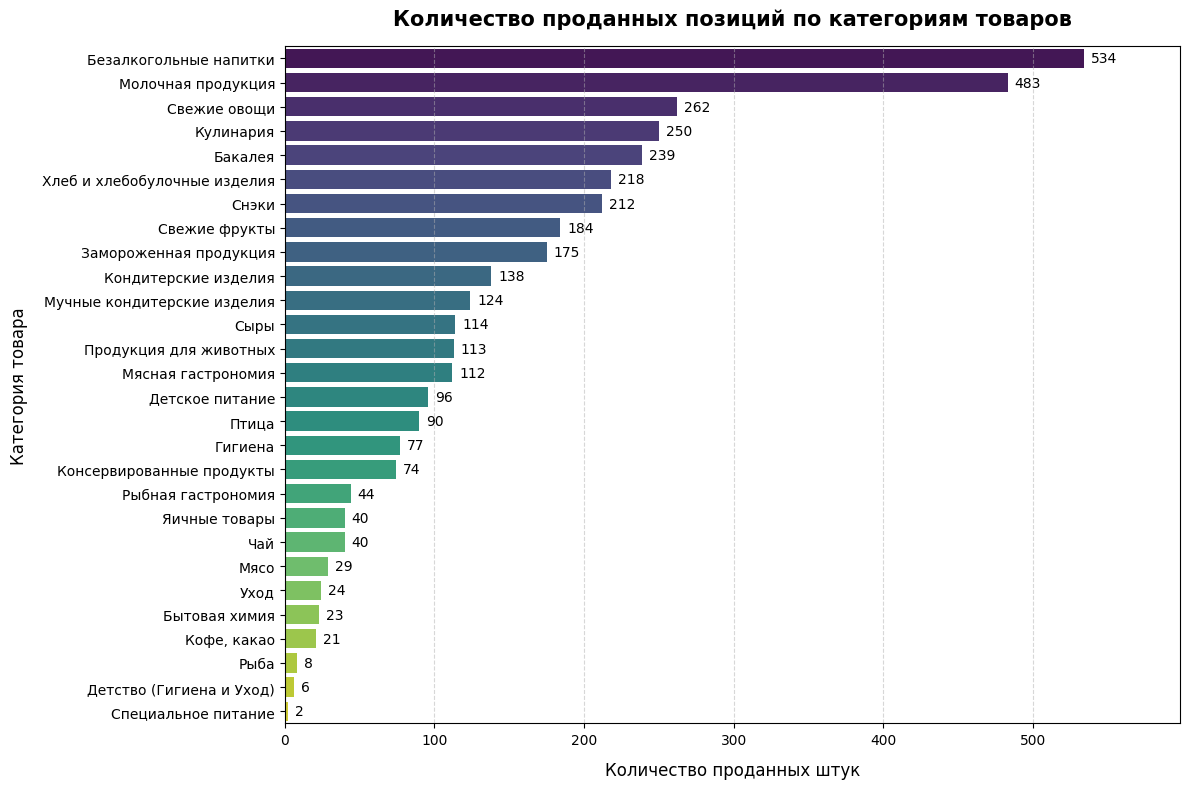

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Объединяем заказы и справочник товаров по общему столбцу product_id
df = pd.merge(orders, products, on='product_id', how='left')

# 2. Считаем количество проданных штук по каждой категории (level1) и сортируем по убыванию
category_sales = (
    df.groupby('level1', as_index=False)['quantity']
    .sum()
    .sort_values(by='quantity', ascending=False)
)
category_sales.columns = ['Категория', 'Продано штук']
# Выводим таблицу (первая строчка покажет категорию-лидера)
display(category_sales)

# 3. Строим читаемый горизонтальный bar chart
plt.figure(figsize=(12, 8))
ax = sns.barplot(
    data=category_sales, x='Продано штук', y='Категория', palette='viridis'
)
# Подписываем точное количество штук рядом с каждым столбцом
for container in ax.containers:
  ax.bar_label(container, fmt='%.0f', padding=5, fontsize=10)

plt.title(
    'Количество проданных позиций по категориям товаров',
    fontsize=15,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Количество проданных штук', fontsize=12, labelpad=10)
plt.ylabel('Категория товара', fontsize=12, labelpad=10)

# Увеличиваем отступ справа, чтобы цифры у самого длинного столбца не упирались в рамку
plt.xlim(0, category_sales['Продано штук'].max() * 1.12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Если таблица df еще не объединена, раскомментируйте строку ниже:
# df = pd.merge(orders, products, on='product_id', how='left')

# 1. Группируем по категории (level1) и подкатегории (level2), считаем сумму штук
subcat_sales = (
    df.groupby(['level1', 'level2'], as_index=False)['quantity']
    .sum()
    .sort_values(by=['level1', 'quantity'], ascending=[True, False])
)
# 2. Добавляем долю (%) каждой подкатегории внутри своей категории level1
subcat_sales['Доля в категории, %'] = (
    subcat_sales['quantity']
    / subcat_sales.groupby('level1')['quantity'].transform('sum')
    * 100
).round(2)

# 3. Переименовываем столбцы для наглядности
subcat_sales.columns = [
    'Категория (level1)',
    'Подкатегория (level2)',
    'Продано штук',
    'Доля в категории, %',
]
# Чтобы в Colab отобразились все строки таблицы без сокращения точками (...)
pd.set_option('display.max_rows', None)

# Выводим расчетную таблицу
display(subcat_sales)

,Категория (level1),Подкатегория (level2),Продано штук,"Доля в категории, %"
10,Бакалея,Сухие блюда быстрого приготовления,38,15.90
3,Бакалея,"Крупы, бобовые",30,12.55
1,Бакалея,Зерновые для завтраков,24,10.04
4,Бакалея,Макаронные изделия,24,10.04
9,Бакалея,Соусы,24,10.04
2,Бакалея,Ингредиенты для готовки,21,8.79
6,Бакалея,Пряности,21,8.79
5,Бакалея,Мука и мучные смеси,19,7.95
7,Бакалея,Растительные масла,18,7.53
8,Бакалея,Сахар,11,4.60


Топ-3 категории по продажам: ['Безалкогольные напитки', 'Молочная продукция', 'Свежие овощи']


/tmp/ipykernel_1821/3899019115.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
/tmp/ipykernel_1821/3899019115.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
/tmp/ipykernel_1821/3899019115.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


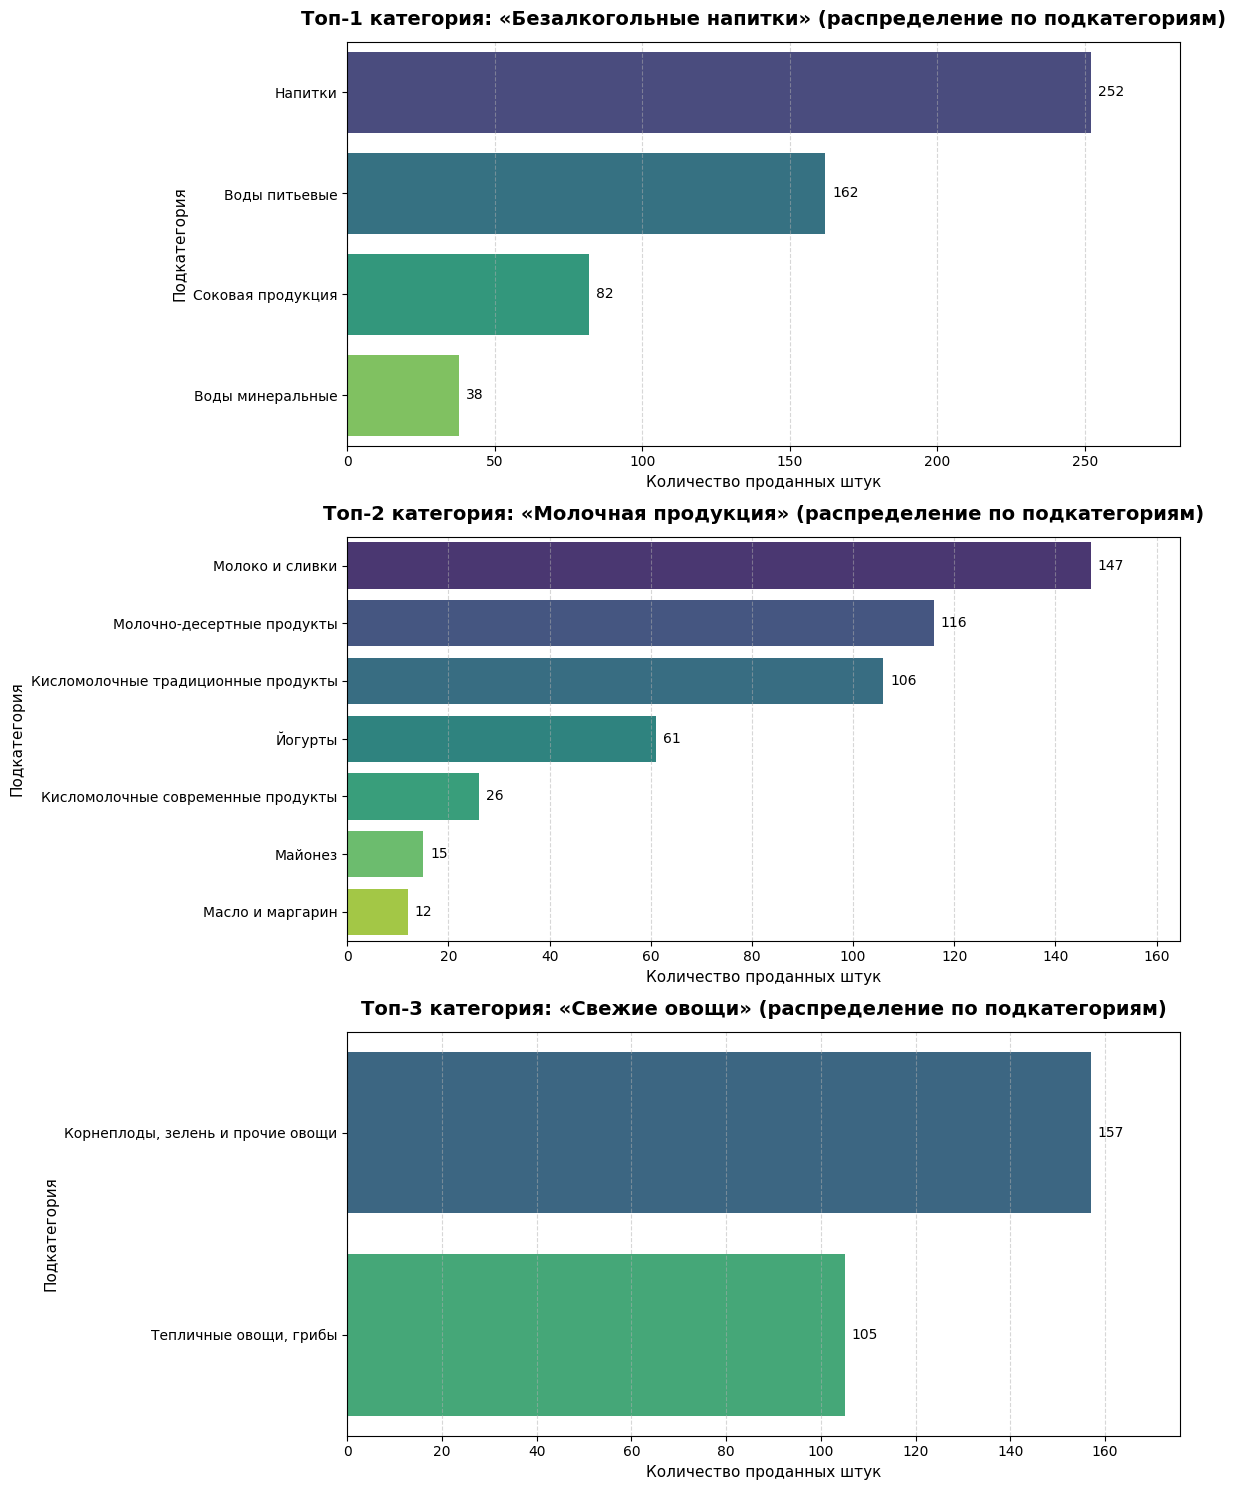

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Находим названия топ-3 категорий по общему количеству проданных штук
top3_categories = (
    df.groupby('level1')['quantity']
    .sum()
    .sort_values(ascending=False)
    .head(3)
    .index.tolist()
)

print('Топ-3 категории по продажам:', top3_categories)
# 2. Фильтруем данные только по топ-3 категориям и группируем по подкатегориям
top3_subcats = (
    df[df['level1'].isin(top3_categories)]
    .groupby(['level1', 'level2'], as_index=False)['quantity']
    .sum()
)

# 3. Строим 3 отдельных горизонтальных графика (один под другим для удобного чтения длинных названий)
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 15))

for i, category in enumerate(top3_categories):
  # Берем данные только для текущей категории и сортируем по убыванию продаж
  cat_data = top3_subcats[top3_subcats['level1'] == category].sort_values(
      by='quantity', ascending=False
  )

  # Рисуем горизонтальный bar chart
  ax = sns.barplot(
      data=cat_data, x='quantity', y='level2', ax=axes[i], palette='viridis'
  )
   # Добавляем точные числа рядом со столбцами
  for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=5, fontsize=10)

  # Настраиваем заголовки и оси для каждого подграфика
  ax.set_title(
      f'Топ-{i+1} категория: «{category}» (распределение по подкатегориям)',
      fontsize=14,
      fontweight='bold',
      pad=12,
  )
  ax.set_xlabel('Количество проданных штук', fontsize=11)
  ax.set_ylabel('Подкатегория', fontsize=11)
# Добавляем запас справа 12%, чтобы цифры не выходили за рамку
  ax.set_xlim(0, cat_data['quantity'].max() * 1.12)
  ax.grid(axis='x', linestyle='--', alpha=0.5)

# Автоматически выравниваем расстояния между графиками, чтобы заголовки не перекрывались
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. Переводим столбец с датой и временем в формат datetime (если это еще не сделано)
orders['accepted_at'] = pd.to_datetime(orders['accepted_at'])

# 2. Считаем итоговую стоимость каждой строчки в заказе (текущая цена * количество)
orders['total_sum'] = orders['price'] * orders['quantity']

# 3. Фильтруем заказы только за 13 января 2022 года
orders_13_jan = orders[orders['accepted_at'].dt.date == pd.to_datetime('2022-01-13').date()]

# 4. Группируем по номеру чека (order_id), чтобы получить полную сумму каждого чека
checks_13_jan = orders_13_jan.groupby('order_id')['total_sum'].sum()
# 5. Считаем средний чек (среднее арифметическое по всем чекам за день)
avg_check = checks_13_jan.mean()

print(f'Количество чеков за 13.01.2022: {len(checks_13_jan)}')
print(f'Общая выручка за день: {checks_13_jan.sum():.2f}')
print(f'Средний чек 13.01.2022: {avg_check:.2f}')

Количество чеков за 13.01.2022: 544
Общая выручка за день: 498107.00
Средний чек 13.01.2022: 915.64


,is_promo,quantity,"Доля, %"
0,Без промоакции,79,69.3
1,По промоакции,35,30.7


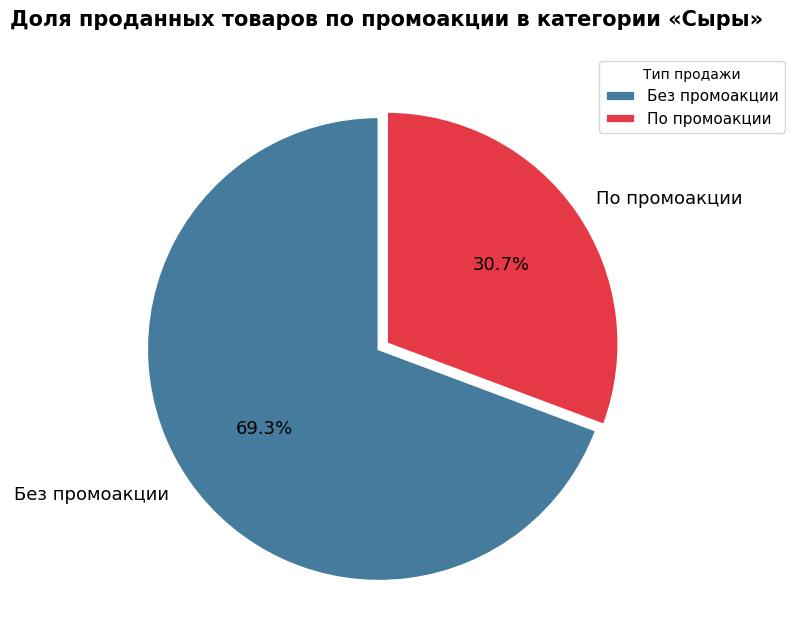

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Если таблица df еще не объединена, раскомментируйте строку ниже:
# df = pd.merge(orders, products, on='product_id', how='left')

# 1. Фильтруем данные только по категории «Сыры»
cheese_df = df[df['level1'] == 'Сыры'].copy()

# 2. Определяем, продан ли товар по промоакции (базовая цена не равна фактической)
cheese_df['is_promo'] = np.where(
    cheese_df['regular_price'] != cheese_df['price'],
    'По промоакции',
    'Без промоакции',
)

# 3. Считаем количество проданных штук (quantity) по группам и долю в процентах
promo_summary = cheese_df.groupby('is_promo', as_index=False)['quantity'].sum()
promo_summary['Доля, %'] = (
    promo_summary['quantity'] / promo_summary['quantity'].sum() * 100
).round(2)

# Выводим расчетную таблицу на экран
display(promo_summary)

# 4. Строим круговую диаграмму (pie chart)
plt.figure(figsize=(8, 8))

plt.pie(
    promo_summary['quantity'],
    labels=promo_summary['is_promo'],
    autopct='%1.1f%%',  # Выводит доли в процентах с одним знаком после запятой
    startangle=90,  # Начинает отрисовку сверху (от 12 часов)
    colors=['#457B9D', '#E63946'],  # Спокойный синий и акцентный красный
    explode=(0.04, 0),  # Слегка отделяет один сектор для наглядности
    textprops={'fontsize': 13},  # Размер шрифта подписей и процентов
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2,
    },  # Белая граница между секторами
)

plt.title(
    'Доля проданных товаров по промоакции в категории «Сыры»',
    fontsize=15,
    fontweight='bold',
    pad=20,
)
plt.legend(
    title='Тип продажи', loc='upper right', fontsize=11, bbox_to_anchor=(1.2, 1)
)
plt.tight_layout()
plt.show()


,level1,revenue,total_cost,margin_rub,margin_pct
1,Безалкогольные напитки,46107,25734,20373,44.19
10,Кулинария,40840,22388,18452,45.18
6,Замороженная продукция,27714,14615,13099,47.26
11,Молочная продукция,37582,25089,12493,33.24
13,Мясная гастрономия,24150,13920,10230,42.36
21,Снэки,22477,12895,9582,42.63
19,Свежие овощи,33222,24216,9006,27.11
0,Бакалея,21766,13589,8177,37.57
20,Свежие фрукты,27009,19130,7879,29.17
23,Сыры,19824,12350,7474,37.70


/tmp/ipykernel_1821/776791008.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(
/tmp/ipykernel_1821/776791008.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(


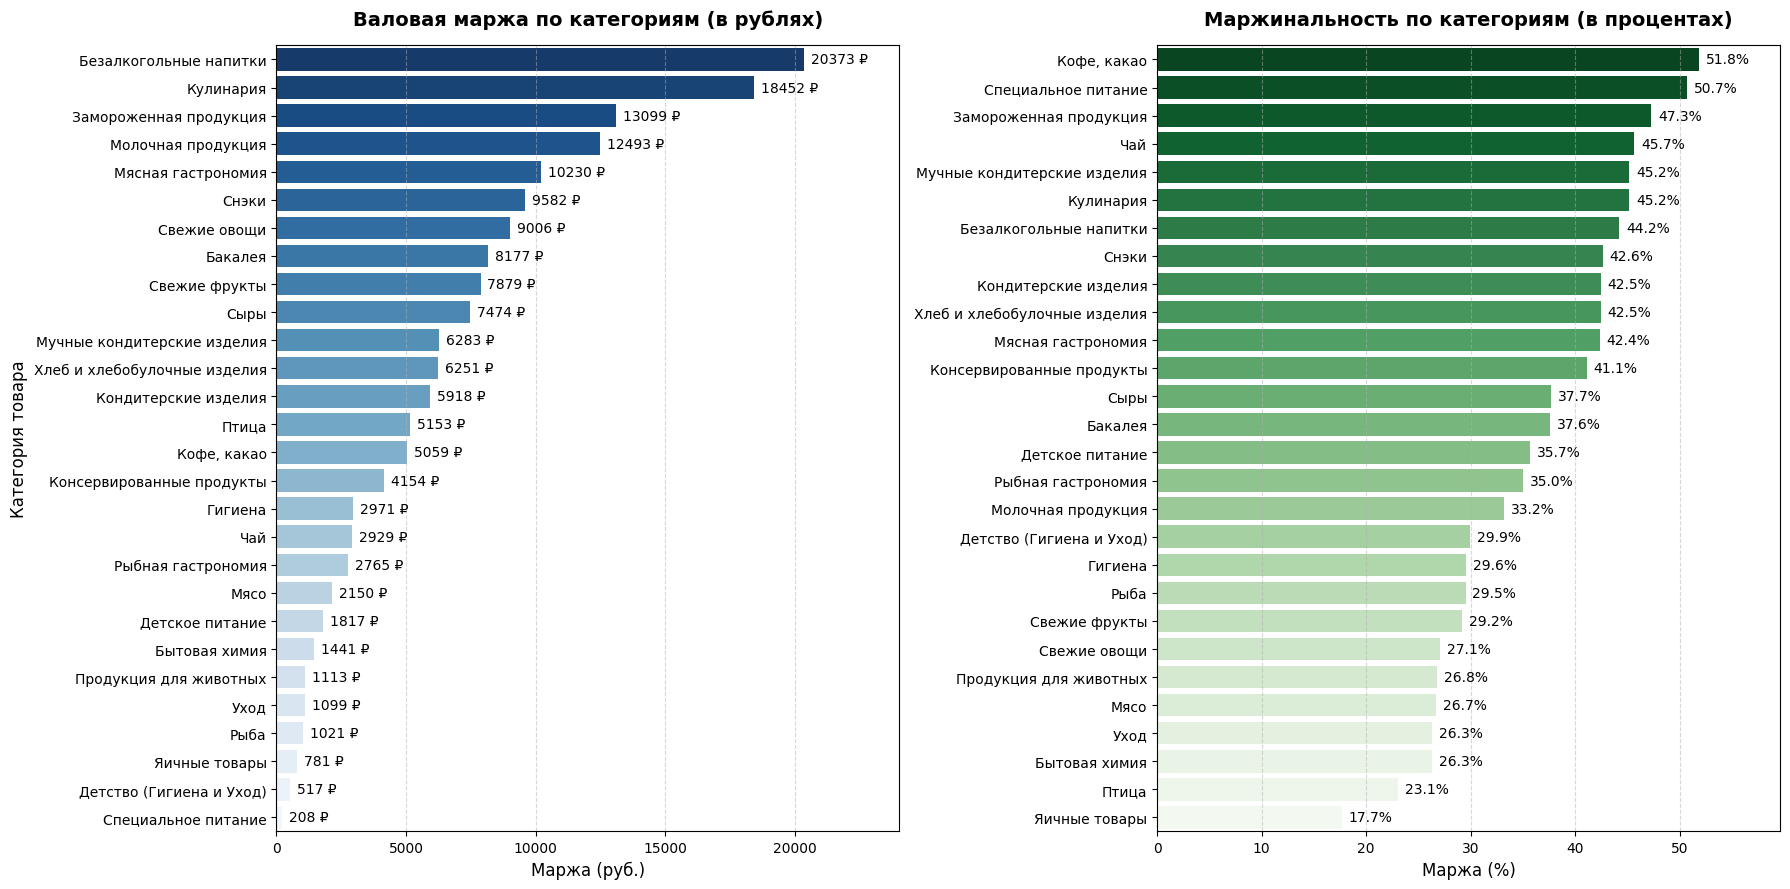

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Считаем выручку и себестоимость каждой строчки в чеке
df['revenue'] = df['price'] * df['quantity']
df['total_cost'] = df['cost_price'] * df['quantity']

# 2. Группируем по категориям (level1) и суммируем выручку и себестоимость
margin_df = df.groupby('level1', as_index=False)[['revenue', 'total_cost']].sum()

# 3. Рассчитываем маржу в рублях и в процентах (маржинальность)
margin_df['margin_rub'] = margin_df['revenue'] - margin_df['total_cost']
margin_df['margin_pct'] = (
    margin_df['margin_rub'] / margin_df['revenue'] * 100
).round(2)

# Выводим итоговую расчетную таблицу (отсортированную по марже в рублях)
display(margin_df.sort_values(by='margin_rub', ascending=False))

# 4. Визуализируем результат с помощью 2 горизонтальных bar chart
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 9))

# --- График 1: Маржа в рублях ---
df_rub = margin_df.sort_values(by='margin_rub', ascending=False)
ax1 = sns.barplot(
    data=df_rub, x='margin_rub', y='level1', ax=axes[0], palette='Blues_r'
)

for container in ax1.containers:
  ax1.bar_label(container, fmt='%.0f ₽', padding=5, fontsize=10)

ax1.set_title(
    'Валовая маржа по категориям (в рублях)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
ax1.set_xlabel('Маржа (руб.)', fontsize=12)
ax1.set_ylabel('Категория товара', fontsize=12)
ax1.set_xlim(0, df_rub['margin_rub'].max() * 1.18)
ax1.grid(axis='x', linestyle='--', alpha=0.5)

# --- График 2: Маржа в процентах ---
df_pct = margin_df.sort_values(by='margin_pct', ascending=False)
ax2 = sns.barplot(
    data=df_pct, x='margin_pct', y='level1', ax=axes[1], palette='Greens_r'
)

for container in ax2.containers:
  ax2.bar_label(container, fmt='%.1f%%', padding=5, fontsize=10)

ax2.set_title(
    'Маржинальность по категориям (в процентах)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
ax2.set_xlabel('Маржа (%)', fontsize=12)
ax2.set_ylabel('')  # Убираем дублирующую подпись оси Y на втором графике для чистоты
ax2.set_xlim(0, df_pct['margin_pct'].max() * 1.15)
ax2.grid(axis='x', linestyle='--', alpha=0.5)

# Автоматически выравниваем расстояние между двумя графиками, чтобы подписи категорий не наезжали на левый график
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import pandas as pd

# 1. Считаем выручку по каждой строке (если еще не посчитана)
df['revenue'] = df['price'] * df['quantity']

# 2. Группируем данные по подкатегориям level2 (при необходимости можно заменить на 'name' или 'level1')
abc_df = df.groupby('level2', as_index=False)[['quantity', 'revenue']].sum()


# Функция для присвоения группы A, B или C по накопительной доле
def get_abc_group(cum_share):
  if cum_share <= 0.80:
    return 'A'
  elif cum_share <= 0.95:
    return 'B'
  else:
    return 'C'


# --- 3. ABC-анализ по количеству продаж (quantity) ---
abc_df = abc_df.sort_values(by='quantity', ascending=False)
abc_df['qty_share'] = abc_df['quantity'] / abc_df['quantity'].sum()
abc_df['qty_cum_share'] = abc_df['qty_share'].cumsum()
abc_df['ABC_quantity'] = abc_df['qty_cum_share'].apply(get_abc_group)

# --- 4. ABC-анализ по сумме продаж (revenue) ---
abc_df = abc_df.sort_values(by='revenue', ascending=False)
abc_df['rev_share'] = abc_df['revenue'] / abc_df['revenue'].sum()
abc_df['rev_cum_share'] = abc_df['rev_share'].cumsum()
abc_df['ABC_revenue'] = abc_df['rev_cum_share'].apply(get_abc_group)

# --- 5. Создаем итоговый столбец на основе двух анализов (например, AA, AB, BC) ---
abc_df['ABC_total'] = abc_df['ABC_quantity'] + abc_df['ABC_revenue']

# Оставляем только нужные для отчета столбцы и выводим таблицу
result_abc = abc_df[[
    'level2',
    'quantity',
    'ABC_quantity',
    'revenue',
    'ABC_revenue',
    'ABC_total',
]].copy()
result_abc.columns = [
    'Подкатегория',
    'Количество, шт.',
    'Группа (кол-во)',
    'Сумма продаж, руб.',
    'Группа (сумма)',
    'Итоговая группа ABC',
]

# Выводим итоговую таблицу (отсортированную по сумме продаж)
display(result_abc)

# Дополнительно: посмотрим, сколько подкатегорий попало в каждую итоговую группу (AA, AB и т.д.)
print('\nРаспределение по итоговым группам:')
print(result_abc['Итоговая группа ABC'].value_counts())


,Подкатегория,"Количество, шт.",Группа (кол-во),"Сумма продаж, руб.",Группа (сумма),Итоговая группа ABC
10,Готовые блюда,248,A,40356,A,AA
51,Напитки,252,A,24123,A,AA
50,Мясо птицы охлажденное,90,A,22349,A,AA
85,"Тепличные овощи, грибы",105,A,18329,A,AA
72,Снэки соленые,180,A,17293,A,AA
94,"Цитрусовые, семечковые и прочие плоды",108,A,16818,A,AA
18,Замороженные полуфабрикаты,73,A,15374,A,AA
40,Молоко и сливки,147,A,14902,A,AA
33,"Корнеплоды, зелень и прочие овощи",157,A,14893,A,AA
92,Хлеб и хлебобулочные изделия,218,A,14724,A,AA



Распределение по итоговым группам:
Итоговая группа ABC
CC    32
AA    23
BB    15
CB    10
BA     9
AB     5
BC     4
AC     2
Name: count, dtype: int64
